# Public GENCO-OPF inference on IEEE14

This example runs the actual GENCO model on a small, public electrical fixture using the official GraphKit dataset processor, the released normalizer, and the OPF input masks. It needs acquired weights and the model environment, but **no private electrical inputs or AC solver**.

The raw fixture is pinned to the same official GraphKit commit as the model adapter. Its ten public files match the upstream Git blob IDs and are SHA-256 verified before processing. This public small-case example is separate from the Texas2k study. It demonstrates compatibility, not a held-out accuracy benchmark, a Texas2k result, a fine-tuning improvement claim, or an AC-feasibility certificate.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import pandas as pd
from IPython.display import display, JSON, Image

ROOT = Path.cwd()
if not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'artifacts/model_catalog.json').is_file(), 'Run from this repository or its notebooks directory.'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT = ROOT / 'outputs' / ('notebook_' + RUN_ID)
OUT.mkdir(parents=True)


In [2]:
from genco_ops.catalog import models
from genco_ops.public_genco_demo import verify_public_data, run_public_demo
MODEL_ID = 'texas2k.genco_opf.base'
SCENARIO = 0
manifest = verify_public_data(ROOT)
display(JSON({'source': manifest['source_repository'], 'commit': manifest['source_commit'], 'files': len(manifest['files']), 'public_git_tree_blob_parity': manifest['public_git_tree_blob_parity']}))
display(pd.DataFrame([{key: row[key] for key in ('model_id', 'role', 'weights_ready')} for row in models(ROOT, 'texas2k') if row['family'] == 'genco_opf']))

<IPython.core.display.JSON object>

,model_id,role,weights_ready
0,texas2k.genco_opf.G100,intermediate,True
1,texas2k.genco_opf.G100_to_R400,final,True
2,texas2k.genco_opf.G100_to_W400,final,True
3,texas2k.genco_opf.G500,final,True
4,texas2k.genco_opf.base,base,True


In [3]:
row = next(row for row in models(ROOT) if row['model_id'] == MODEL_ID)
if not row['weights_ready']:
    result = {'status': 'UNAVAILABLE_MODEL_ASSETS_NOT_A_PASSED_DEMO', 'model_id': MODEL_ID, 'acquisition': 'Follow README model acquisition; no Texas inputs are required.'}
else:
    result = run_public_demo(ROOT, OUT / 'public_ieee14', model_id=MODEL_ID, scenario=SCENARIO)
display(JSON({'kind': 'public_genco_inference', **result}))

Processing...


LOADING DATA


Processing scenarios:   0%|          | 0/72 [00:00<?, ?it/s]

Processing scenarios:  17%|█▋        | 12/72 [00:00<00:00, 117.96it/s]

Processing scenarios:  35%|███▍      | 25/72 [00:00<00:00, 123.06it/s]

...

Processing scenarios:  72%|███████▏  | 52/72 [00:00<00:00, 124.34it/s]

Processing scenarios:  90%|█████████ | 65/72 [00:00<00:00, 125.15it/s]

Processing scenarios: 100%|██████████| 72/72 [00:00<00:00, 125.70it/s]


Done!


<IPython.core.display.JSON object>

The next tables are decoded predictions: voltage magnitude in per unit, angle in radians, active power in MW, and reactive power in MVAr. The output may violate physical or operating constraints. A complete application must check residuals and use the appropriate AC audit.

This public example uses only the released GENCO-OPF checkpoint. Use notebook 03 for the actual Texas-adapted checkpoints and their exact input contract. The released normalizer is always loaded unchanged.

,fixture_bus_index,vm_pu,va_rad,pg_mw,qg_mvar
0,0,1.054314,0.000000,339.780500,-79.850810
1,1,1.058738,-0.118788,58.708603,84.558395
2,2,1.058829,-0.222507,0.000000,41.083576
3,3,1.034303,-0.210323,0.000000,0.000000
4,4,1.030722,-0.189109,0.000000,0.000000
5,5,1.043667,-0.321684,0.000000,-23.899113
6,6,1.036998,-0.388866,0.000000,0.000000
7,7,1.028719,-0.366032,0.000000,-3.995909
8,8,1.043527,-0.396342,0.000000,0.000000
9,9,1.035461,-0.399516,0.000000,0.000000


,fixture_generator_index,pg_mw
0,0,339.780500
1,1,58.708603
2,2,0.000000
3,3,0.000000
4,4,0.000000


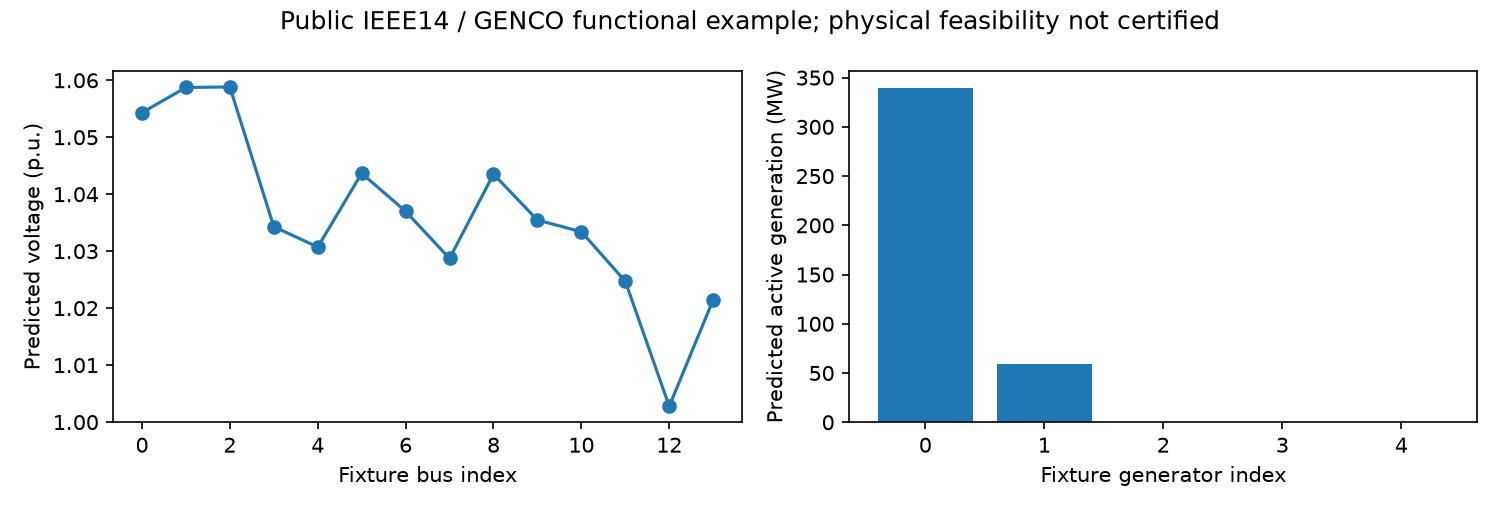

In [4]:
if result['status'].startswith('PASS_'):
    bus = pd.read_csv(OUT / 'public_ieee14/predicted_bus.csv')
    generator = pd.read_csv(OUT / 'public_ieee14/predicted_generator.csv')
    display(bus.round(6))
    display(generator.round(6))
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    axes[0].plot(bus.fixture_bus_index, bus.vm_pu, marker='o')
    axes[0].set(xlabel='Fixture bus index', ylabel='Predicted voltage (p.u.)')
    axes[1].bar(generator.fixture_generator_index, generator.pg_mw)
    axes[1].set(xlabel='Fixture generator index', ylabel='Predicted active generation (MW)')
    fig.suptitle('Public IEEE14 / GENCO functional example; physical feasibility not certified')
    fig.tight_layout()
    fig.savefig(OUT / 'public_ieee14/prediction.png', dpi=150)
    plt.close(fig)
    display(Image(filename=str(OUT / 'public_ieee14/prediction.png')))
else:
    print('No numerical result claimed. Acquire the documented model assets and rerun.')